# Razão e limites cruzados

**Uma vazão precisa acompanhar a outra. Nos transitórios, a ordem importa.**

Aqui comparo dois comandos: pedir ar e combustível juntos, ou permitir mais
combustível só depois de o ar chegar. Execute de cima para baixo; o painel está no fim.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as controles
from scipy.optimize import curve_fit
from IPython.display import display

plt.rcParams.update({"figure.figsize": (9, 3), "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

## O processo

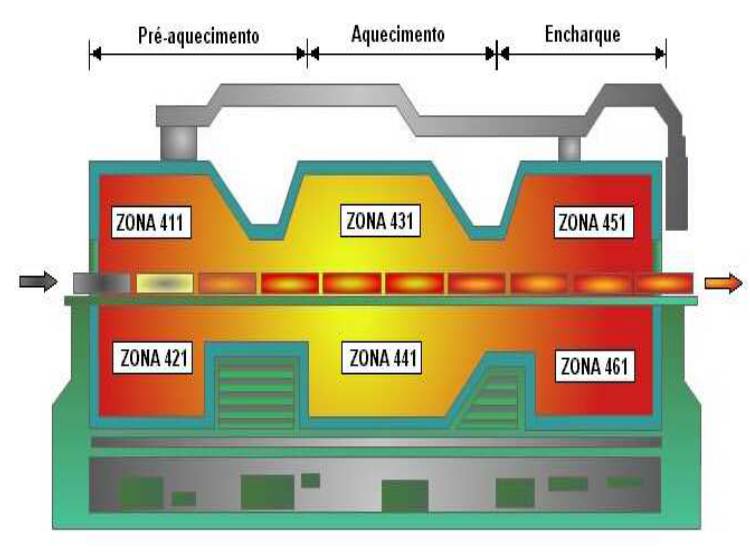

Duas válvulas alimentam uma zona de um forno. Vou usar modelos publicados para
as malhas de gás e ar, em desvios em relação ao ponto de operação:

$$G_g(s)=\frac{0{,}25e^{-s}}{4{,}78s+1},\qquad
G_a(s)=\frac{0{,}51e^{-2s}}{7{,}16s+1}.$$

Entrada: abertura em pontos percentuais. Saída: desvio de vazão em mil Nm³/h.
O tempo está em segundos. No painel, normalizo os fluxos para enxergar a sequência;
a razão escolhida ali **não é uma razão estequiométrica do forno**.

In [2]:
nomes = ['Gás', 'Ar']
modelos = np.array([[0.25, 4.78, 1.0], [0.51, 7.16, 2.0]])  # K, τ, θ
unidade_tempo = 'Tempo (s)'
unidade_saida = 'Desvio de vazão (mil Nm³/h)'

## Primeiro, só a regra

Se peço 0,60 de combustível, mas o ar disponível só permite 0,40, o seletor
limita o pedido. O `min` segura o combustível; o `max` mantém o pedido de ar.

In [3]:
def referencias_cruzadas(demanda, combustivel, ar, razao):
    referencia_ar = max(razao * demanda, razao * combustivel)
    referencia_combustivel = min(demanda, ar / razao)
    return np.array([referencia_combustivel, referencia_ar])

pedido = referencias_cruzadas(demanda=0.60, combustivel=0.30, ar=0.44, razao=1.10)
print(f'Combustível permitido: {pedido[0]:.2f}; pedido de ar: {pedido[1]:.2f}')

Combustível permitido: 0.40; pedido de ar: 0.66


## Identificar com ruído

Aplico um degrau pequeno e adiciono ruído de medição. Estes são dados simulados
pelos modelos, não medições industriais. Vou estimar ganho, constante de tempo
e atraso apenas com esse ensaio.

In [4]:
def resposta_modelo(tempo, entrada, parametros):
    ganho, constante, atraso = parametros
    variacoes = np.diff(entrada, prepend=0)
    saida = np.zeros_like(tempo)
    for indice in np.flatnonzero(variacoes):
        decorrido = np.maximum(tempo - tempo[indice] - atraso, 0)
        saida += ganho * variacoes[indice] * (1 - np.exp(-decorrido / constante))
    return saida

In [5]:
tempo_ensaio = np.arange(0, 60.1, 0.2)
entrada_ensaio = np.where(tempo_ensaio >= 5, 5.0, 0.0)  # Degrau de 5 pontos percentuais.
desvio_ruido = 0.025
gerador = np.random.default_rng(37)
medicoes_ensaio = np.array([resposta_modelo(tempo_ensaio, entrada_ensaio, modelo)
                           + gerador.normal(0, desvio_ruido, len(tempo_ensaio))
                           for modelo in modelos])

In [6]:
def identificar(tempo, entrada, medicao):
    def previsao(tempo, ganho, constante, atraso):
        return resposta_modelo(tempo, entrada, [ganho, constante, atraso])
    parametros, _ = curve_fit(previsao, tempo, medicao,
                             p0=[1, 8, 1], bounds=([0.001, 0.1, 0], [100, 60, 10]))
    return parametros

estimativas = np.array([identificar(tempo_ensaio, entrada_ensaio, medicao)
                       for medicao in medicoes_ensaio])
for nome, valores in zip(nomes, estimativas):
    print(f"{nome}: K={valores[0]:.3f}; τ={valores[1]:.2f}; θ={valores[2]:.2f}")

Gás: K=0.250; τ=4.80; θ=1.01
Ar: K=0.511; τ=7.29; θ=1.96


## Validar em outro ensaio

Agora a entrada sobe, desce e volta. Gero novas medições e mantenho os parâmetros
estimados. Quanto menor o RMSE, mais próximas estão previsão e medição, nas unidades
do gráfico. Compare também o formato das curvas.

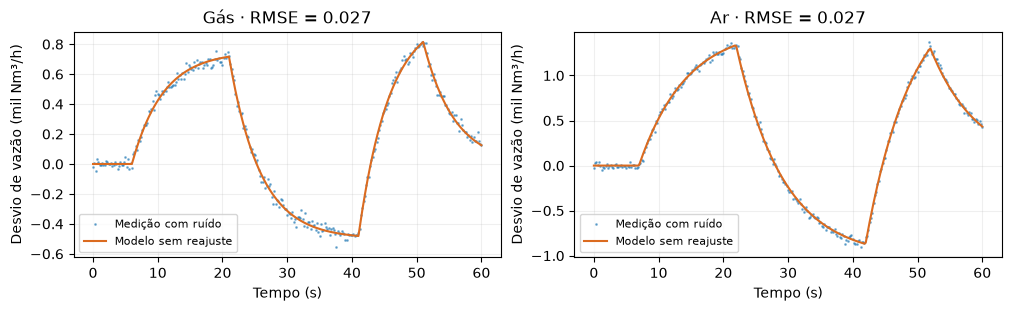

In [7]:
entrada_validacao = np.select([tempo_ensaio < 5, tempo_ensaio < 20,
                                  tempo_ensaio < 40, tempo_ensaio < 50],
                                 [0, 3, -2, 4], default=0).astype(float)

gerador_validacao = np.random.default_rng(2026)
medicoes_validacao = np.array([resposta_modelo(tempo_ensaio, entrada_validacao, modelo)
                             + gerador_validacao.normal(0, desvio_ruido, len(tempo_ensaio))
                             for modelo in modelos])
previsoes_validacao = np.array([resposta_modelo(tempo_ensaio, entrada_validacao, parametros)
                              for parametros in estimativas])
erros_validacao = medicoes_validacao - previsoes_validacao
rmse_validacao = np.sqrt(np.mean(erros_validacao ** 2, axis=1))

figura, eixos = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for nome, medicao, previsao, rmse, eixo in zip(
        nomes, medicoes_validacao, previsoes_validacao, rmse_validacao, eixos):
    eixo.plot(tempo_ensaio, medicao, '.', ms=2, alpha=0.5, label='Medição com ruído')
    eixo.plot(tempo_ensaio, previsao, color='#db6b20', label='Modelo sem reajuste')
    eixo.set(title=f'{nome} · RMSE = {rmse:.3f}', xlabel=unidade_tempo,
             ylabel=unidade_saida)
    eixo.legend(fontsize=8)
plt.show()

## Sintonia IMC

Uso as estimativas: $K_c=\tau/[K(\lambda+\theta)]$ e $T_i=\tau$.
Aqui, $\lambda=8$ s para as duas malhas. Assim, a comparação destaca a lógica de razão.
Normalizo os ganhos antes de usar o PI no painel.

In [8]:
def sintonia_imc(parametros, tempo_resposta):
    ganho, constante, atraso = parametros
    ganho_controlador = constante / (ganho * (tempo_resposta + atraso))
    tempo_integral = constante
    return ganho_controlador, tempo_integral

def comando_pi(erro, integral, ganho, tempo_integral, passo):
    tentativa = ganho * erro + integral
    comando = np.clip(tentativa, 0, 1)
    # Não acumulo integral quando ela empurra além do limite.
    if 0 < tentativa < 1 or (tentativa >= 1 and erro < 0) or (tentativa <= 0 and erro > 0):
        integral += ganho * erro * passo / tempo_integral
    return comando, integral

parametros_normalizados = estimativas.copy()
parametros_normalizados[:, 0] /= modelos[:, 0]
sintonias = np.array([sintonia_imc(parametros, 8) for parametros in parametros_normalizados])
print('Kc e Ti das malhas normalizadas:', np.round(sintonias, 3))

Kc e Ti das malhas normalizadas: [[0.533 4.797]
 [0.73  7.293]]


## A simulação

A demanda sobe em 40 s e volta em 140 s. As duas estratégias usam os mesmos modelos,
PIs e ruído. Na curva superior, valores abaixo da razão-alvo mostram falta relativa
de ar. A curva inferior mostra quem avança primeiro com os limites cruzados.

In [9]:
def simular_razao(demanda_final=0.65, razao=1.10, ruido=0.003, cruzado=True, passo=0.05):
    tempo = np.arange(0, 240 + passo / 2, passo)
    demanda = np.where((tempo >= 40) & (tempo < 140), demanda_final, 0.30)
    vazoes = np.zeros((len(tempo), 2))
    comandos = np.zeros_like(vazoes)
    vazoes[0] = [0.30, razao * 0.30]
    comandos[0] = vazoes[0]
    integrais = vazoes[0].copy()
    gerador = np.random.default_rng(42)
    atenuacoes = np.exp(-passo / modelos[:, 1])
    atrasos = np.rint(modelos[:, 2] / passo).astype(int)
    for indice in range(len(tempo) - 1):
        medidas = np.maximum(vazoes[indice] + gerador.normal(0, ruido, 2), 0)
        referencias = (referencias_cruzadas(demanda[indice], *medidas, razao)
                       if cruzado else np.array([demanda[indice], razao * demanda[indice]]))
        for canal in range(2):
            comandos[indice, canal], integrais[canal] = comando_pi(
                referencias[canal] - medidas[canal], integrais[canal],
                *sintonias[canal], passo)
            anterior = indice - atrasos[canal]
            atrasado = comandos[anterior, canal] if anterior >= 0 else vazoes[0, canal]
            vazoes[indice + 1, canal] = (atenuacoes[canal] * vazoes[indice, canal]
                                        + (1 - atenuacoes[canal]) * atrasado)
    comandos[-1] = comandos[-2]
    return tempo, vazoes, comandos

In [10]:
def explorar_razao(demanda_final=0.65, razao=1.10, ruido=0.003):
    tempo, vazoes_cruzadas, _ = simular_razao(demanda_final, razao, ruido, True)
    _, vazoes_paralelas, _ = simular_razao(demanda_final, razao, ruido, False)
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True, constrained_layout=True)
    for vazoes, nome, cor in [(vazoes_paralelas, 'Pedidos juntos', '#df752c'),
                              (vazoes_cruzadas, 'Limites cruzados', '#2374ab')]:
        proporcao = vazoes[:, 1] / vazoes[:, 0]
        eixos[0].plot(tempo, proporcao, label=nome, color=cor)
    eixos[0].axhline(razao, ls='--', color='#555555', label='Razão-alvo')
    eixos[0].set(ylabel='Ar / combustível', title='A proporção durante a mudança')
    eixos[0].legend(fontsize=8)
    eixos[1].plot(tempo, vazoes_cruzadas[:, 0], label='Combustível')
    eixos[1].plot(tempo, vazoes_cruzadas[:, 1] / razao, label='Ar equivalente')
    eixos[1].set(xlabel='Tempo (s)', ylabel='Fluxo normalizado', title='Com limites cruzados')
    eixos[1].legend(fontsize=8)
    plt.show()

painel_razao = controles.interactive(
    explorar_razao,
    demanda_final=controles.FloatSlider(value=0.65, min=0.40, max=0.75, step=0.05,
                                        description='Demanda', continuous_update=False),
    razao=controles.FloatSlider(value=1.10, min=1.00, max=1.30, step=0.05,
                                description='Razão-alvo', continuous_update=False),
    ruido=controles.FloatSlider(value=0.003, min=0, max=0.015, step=0.003,
                                description='Ruído (σ)', readout_format='.3f', continuous_update=False))
display(painel_razao)

interactive(children=(FloatSlider(value=0.65, continuous_update=False, description='Demanda', max=0.75, min=0.…

## O que observar

- **Demanda:** amplia a mudança; os seletores coordenam a subida e a descida.
- **Razão-alvo:** pede mais ar para a mesma demanda de combustível.
- **Ruído:** a lógica age sobre medições imperfeitas. Pode haver pequenas violações da razão.

Limites cruzados coordenam pedidos; não substituem proteção de uma combustão real.
A explicação completa e as referências estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/03_razao_limites_cruzados/README.md).

## Referências

1. Teixeira, B. O. S.; Jota, F. G.; Teixeira, M. H. (2007). *Modelagem, controle e otimização
do processo dos fornos de reaquecimento de placas*. SBA: Controle & Automação, 18(1), 67–93.
[Artigo](https://doi.org/10.1590/S0103-17592007000100006), Tabela 2 e seção 2. Imagem: Figura 2, p. 71.
2. Rivera, D. E.; Morari, M.; Skogestad, S. (1986). *Internal model control. 4. PID controller design*.
[DOI](https://doi.org/10.1021/i200032a041).